# Notebook 2 de 3 — Imágenes manipuladas

A partir de las fotos reales del notebook 1 se generan **tres tipos de imagen para la clase "Manipulada"**:

| Tipo | Qué es | Para qué sirve |
|---|---|---|
| `inpaint_danio` | La foto real con **daño agregado por IA** en una zona de la carrocería (se pega solo esa zona) | Representa el fraude realista: partir de una foto auténtica y agregarle un golpe |
| `inpaint_control` | La **misma foto real**, editada por IA en la misma zona, pero **sin daño** (chapa limpia regenerada) | Obliga al modelo a detectar **la edición** y no la presencia de un golpe |
| `ia_danio` / `ia_sano` | Autos **100 % generados por IA**, con y sin daño | Caso de imagen totalmente sintética |

**Edición de control.** Si todas las imágenes manipuladas tuvieran daño y todas las auténticas no, el modelo aprendería a asociar el golpe con la manipulación, y eso no sirve porque existen golpes reales. Con la edición de control y las fotos reales dañadas del notebook 1, el daño deja de ser una pista.

**Pegado de la zona editada.** Los modelos de *inpainting* regeneran internamente toda la imagen. Si se usara esa salida completa, toda la foto tendría una huella de IA y no habría nada **local** que detectar. Por eso se toma solo la zona generada y se pega sobre la foto original con un borde suave: el resto de los píxeles sigue siendo 100 % real. El detector tiene que encontrar inconsistencias entre la zona editada y el resto de la carrocería.

**Máscaras.** Se guarda la máscara de cada edición, para verificar más adelante si el mapa de calor de Grad-CAM coincide con la zona editada.

**Ejecución**

1. Requiere Colab con **GPU** (T4).
2. Usa como entrada `01_reales/manifest_reales.csv`, generado por el notebook 1.
3. Con `PRUEBA_RAPIDA = True` se procesan 4 fotos (2 con cada modelo); con `False`, todas las fotos sanas.
4. El proceso es **reanudable**: si la ejecución se interrumpe, al volver a correr continúa desde donde quedó.

**Dos modelos de edición.** La mitad de las fotos base se edita con **Stable Diffusion 1.5 inpainting** y la otra mitad con **SDXL inpainting**. SD 1.5 genera daños más marcados, aunque a veces no llega a dibujarlos; SDXL genera daños más sutiles y realistas. Combinar generadores da variedad al dataset y hace que el detector aprenda a encontrar **ediciones en general** y no las huellas de una sola herramienta: en un fraude real no se sabe con qué programa se hizo la edición.

> Tiempos aproximados en una T4: 5 a 8 s por edición con SD 1.5 y 20 a 25 s con SDXL. Con 300 fotos base (600 ediciones) son 2 a 3 horas, que se pueden repartir en varias sesiones. Las imágenes 100 % IA con SDXL-turbo tardan 2 a 3 s cada una.

## 1. Instalación e imports

In [10]:
%pip install -q diffusers transformers accelerate safetensors opencv-python-headless
# torchao viene preinstalada en Colab y su versión choca con diffusers nuevo (error 'FqnToConfig'); no se usa.
%pip uninstall -y -q torchao
# Si es la primera vez en esta sesión: Entorno de ejecución > Reiniciar sesión, y seguir desde la celda siguiente.

In [11]:
import os, sys, gc, csv, time, zlib, random
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO HAY GPU")

PyTorch 2.11.0+cu128 | GPU: Tesla T4


## 2. Configuración

In [12]:
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/deteccion-fraude-v2")
else:
    RAIZ = Path("./deteccion-fraude-v2")

MANIFEST_REALES = RAIZ / "01_reales" / "manifest_reales.csv"
SALIDA          = RAIZ / "02_falsas"
DIR_DANIO       = SALIDA / "inpaint_danio"
DIR_CONTROL     = SALIDA / "inpaint_control"
DIR_MASCARAS    = SALIDA / "mascaras"
DIR_IA          = SALIDA / "ia_completa"
MANIFEST_FALSAS = SALIDA / "manifest_falsas.csv"
for d in [DIR_DANIO, DIR_CONTROL, DIR_MASCARAS, DIR_IA]:
    d.mkdir(parents=True, exist_ok=True)

CANVAS_W, CANVAS_H = 768, 512           # debe coincidir con el notebook 1

# ---------- Modelos de edición (inpainting) ----------
# Se alternan: la mitad de las fotos base con cada uno. Valores ajustados con pruebas previas
# (guidance 12 para SD 1.5; SDXL trabaja a ~1 megapíxel, por eso 1152x768, y con strength 0.99).
MODELOS_INPAINT = [
    {"nombre": "sd15", "repo": "stable-diffusion-v1-5/stable-diffusion-inpainting",
     "ancho": 768, "alto": 512, "pasos": 30, "guidance": 12.0, "strength": 1.0},
    {"nombre": "sdxl", "repo": "diffusers/stable-diffusion-xl-1.0-inpainting-0.1",
     "ancho": 1152, "alto": 768, "pasos": 30, "guidance": 8.0, "strength": 0.99},
]

# ---------- Texto a imagen ----------
MODELO_T2I = "stabilityai/sdxl-turbo"                              # texto -> imagen, pocos pasos

# ---------- Cantidad a generar ----------
FRACCION_BASES_EDITADAS = 1.0     # 1.0 = se editan todas las fotos sanas del notebook 1
N_IA = 200                        # autos 100 % IA: la mitad con daño y la mitad sin daño

# ---------- Modo prueba ----------
PRUEBA_RAPIDA = True
if PRUEBA_RAPIDA:
    N_IA = 4                          # los pasos de inpainting NO se bajan: con pocos pasos el daño no se llega a dibujar

SEMILLA = 42
GEN_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(SEMILLA); np.random.seed(SEMILLA)

df_reales = pd.read_csv(MANIFEST_REALES)
bases = df_reales[df_reales["tipo"] == "sano"].reset_index(drop=True)
bases = bases.sample(frac=FRACCION_BASES_EDITADAS, random_state=SEMILLA).reset_index(drop=True)
if PRUEBA_RAPIDA:
    bases = bases.head(4)
# Asignación alternada de un modelo de edición a cada foto base (las bases ya están mezcladas al azar)
bases["modelo_edicion"] = [MODELOS_INPAINT[i % len(MODELOS_INPAINT)]["nombre"] for i in range(len(bases))]
print(f"Fotos base sanas para editar: {len(bases)}")
print(bases["modelo_edicion"].value_counts().to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fotos base sanas para editar: 4
modelo_edicion
sd15    2
sdxl    2


## 3. Máscaras: zonas de edición

El notebook 1 guardó la posición del auto en cada foto (`caja_x0…caja_y1`). Para cada foto se elige al azar una **zona de la carrocería** y se dibuja una mancha irregular, formada por varias elipses superpuestas, siempre **dentro** de la caja del auto. Las zonas son posiciones relativas a esa caja:

- `parte_baja` (paragolpes, zócalos), `lateral` (puertas), `esquina_izq` / `esquina_der` (guardabarros, ópticas), `parte_alta` (capó, baúl).

Como no se sabe si el auto está de frente, de costado o de atrás, las zonas son genéricas. La mancha ocupa entre el 1,5 % y el 12 % de la imagen, con un objetivo de 2 % a 8 %.

**Pegado local:** `pegar_local` combina la imagen generada con la original usando la máscara con borde suave. Fuera de la máscara, los píxeles quedan **idénticos** a los de la foto real; la celda incluye un chequeo automático de esa condición.

In [13]:
ZONAS = {                       # (x0, x1, y0, y1) como fracción de la caja del auto
    "parte_baja":  (0.10, 0.90, 0.50, 0.80),
    "lateral":     (0.15, 0.85, 0.30, 0.72),
    "esquina_izq": (0.05, 0.40, 0.40, 0.78),
    "esquina_der": (0.60, 0.95, 0.40, 0.78),
    "parte_alta":  (0.20, 0.80, 0.15, 0.50),
}
MIN_FRAC_MASCARA, MAX_FRAC_MASCARA = 0.015, 0.12

def generar_mascara(caja, rng):
    # Mancha irregular = unas pocas elipses superpuestas, con tamaño objetivo entre 2 % y 8 % de la imagen.
    x0, y0, x1, y1 = caja
    bw, bh = x1 - x0, y1 - y0
    area_img = CANVAS_W * CANVAS_H
    for _ in range(20):
        zona = str(rng.choice(list(ZONAS)))
        fx0, fx1, fy0, fy1 = ZONAS[zona]
        cx = x0 + bw * rng.uniform(fx0, fx1)
        cy = y0 + bh * rng.uniform(fy0, fy1)
        n = int(rng.integers(3, 6))
        area_elipse = rng.uniform(0.02, 0.08) * area_img / (n * 0.6)      # las elipses se solapan un poco
        m = np.zeros((CANVAS_H, CANVAS_W), np.uint8)
        for _ in range(n):
            forma = rng.uniform(0.6, 1.6)
            ax = min(np.sqrt(area_elipse * forma / np.pi), bw * 0.3)
            ay = min(ax / forma, bh * 0.3)
            dx = rng.normal(0, bw * 0.05); dy = rng.normal(0, bh * 0.05)
            cv2.ellipse(m, (int(cx + dx), int(cy + dy)), (max(int(ax), 6), max(int(ay), 6)),
                        float(rng.uniform(0, 180)), 0, 360, 255, -1)
        recinto = np.zeros_like(m)
        cv2.rectangle(recinto, (int(x0), int(y0)), (int(x1), int(y1)), 255, -1)
        m = cv2.bitwise_and(m, recinto)
        frac = float((m > 0).mean())
        if MIN_FRAC_MASCARA <= frac <= MAX_FRAC_MASCARA:
            return m, zona, frac
    return None, None, 0.0

def pegar_local(original, generada, mascara, sigma=4):
    # Combina: adentro de la máscara (con borde suave) la imagen generada, afuera la foto original intacta.
    alfa = cv2.GaussianBlur(mascara.astype(np.float32) / 255.0, (0, 0), sigma)[..., None]
    salida = generada.astype(np.float32) * alfa + original.astype(np.float32) * (1 - alfa)
    return np.clip(salida + 0.5, 0, 255).astype(np.uint8)

# Chequeo de la función (sin GPU): fuera de la máscara, la imagen tiene que quedar idéntica
_r = np.random.default_rng(0)
_orig = _r.integers(0, 255, (CANVAS_H, CANVAS_W, 3), dtype=np.uint8)
_gen = 255 - _orig
_m, _z, _f = generar_mascara([100, 100, 600, 450], _r)
_res = pegar_local(_orig, _gen, _m)
_lejos = cv2.dilate(_m, np.ones((41, 41), np.uint8)) == 0
print(f"Chequeo pegado local: zona '{_z}', máscara {_f:.1%} de la imagen; "
      f"píxeles lejos de la máscara idénticos a la original: {bool((_res[_lejos] == _orig[_lejos]).all())}")

Chequeo pegado local: zona 'lateral', máscara 3.4% de la imagen; píxeles lejos de la máscara idénticos a la original: True


## 4. Inpainting: daño agregado y edición de control

Primero se editan las fotos asignadas a **SD 1.5** y después las de **SDXL**, cargando un modelo por vez para que entre en la memoria de la T4. En la primera ejecución los modelos se descargan desde Hugging Face (unos 2 GB y 7 GB).

Para **cada foto base** se hacen dos ediciones **con la misma máscara**:

- `_inpaint`: prompt de daño (abolladura, rayones, paragolpes roto…).
- `_control`: prompt de chapa limpia, del mismo color y sin daño.

Usar la misma máscara en las dos evita que el tamaño o la forma de la mancha delate el tipo de imagen. Si el modelo devuelve una imagen negra (ocurre cuando se activa por error su filtro de seguridad), la foto se omite y queda registrada.

Los archivos se llaman `r0001_inpaint.png` y `r0001_control.png`: el identificador común permite mantener la foto original y sus ediciones **juntas** en train o en test.

In [14]:
# [CARGA_MODELO] Función que carga un modelo de inpainting (se usa más abajo, uno por vez)
from diffusers import AutoPipelineForInpainting

if not torch.cuda.is_available():
    raise RuntimeError("Este notebook necesita GPU: Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU (T4).")

def cargar_inpaint(cfg):
    pipe = AutoPipelineForInpainting.from_pretrained(
        cfg["repo"], torch_dtype=torch.float16, variant="fp16").to("cuda")
    pipe.set_progress_bar_config(disable=True)
    print("Modelo de inpainting cargado:", cfg["repo"])
    return pipe

In [15]:
# Prompts "fuertes": en las pruebas, los más directos fueron los que llegaron a dibujar daño
PROMPTS_DANIO = [
    "car body panel with a deep dent and crumpled bent metal, scratched and peeled paint, collision damage, photo",
    "car bumper cracked and partially torn off, scuffed and scraped paint, collision damage, photo",
    "car door with a large dent and long deep scratches down to bare metal, photo",
    "crushed car fender with bent metal and chipped paint after a crash, photo",
    "car panel with scraped paint and a shallow dent from a parking accident, photo",
]
PROMPT_CONTROL = "clean undamaged car body panel, smooth glossy paint matching the car color, natural reflections, photorealistic"
PROMPT_NEGATIVO = "text, watermark, cartoon, drawing, painting, blurry, deformed, people, extra objects, logo"

def editar(pipe, cfg, foto_np, mascara_np, prompt, semilla):
    # Si el modelo trabaja a otro tamaño (SDXL), se agrandan foto y máscara y después se vuelve a 768x512.
    gen = torch.Generator(device=GEN_DEVICE).manual_seed(int(semilla))
    tam = (cfg["ancho"], cfg["alto"])
    foto_pil, masc_pil = Image.fromarray(foto_np), Image.fromarray(mascara_np)
    if tam != (CANVAS_W, CANVAS_H):
        foto_pil = foto_pil.resize(tam, Image.LANCZOS)
        masc_pil = masc_pil.resize(tam, Image.NEAREST)
    salida = pipe(prompt=prompt, negative_prompt=PROMPT_NEGATIVO,
                  image=foto_pil, mask_image=masc_pil,
                  height=cfg["alto"], width=cfg["ancho"],
                  num_inference_steps=cfg["pasos"], guidance_scale=cfg["guidance"],
                  strength=cfg["strength"], generator=gen).images[0].convert("RGB")
    if salida.size != (CANVAS_W, CANVAS_H):
        salida = salida.resize((CANVAS_W, CANVAS_H), Image.LANCZOS)
    return np.asarray(salida)

COLUMNAS_MANIFEST = ["archivo", "tipo", "base_id", "danio", "zona", "mascara_frac", "prompt",
                     "seed", "modelo", "pasos", "guidance", "timestamp"]
if MANIFEST_FALSAS.exists():
    df_falsas = pd.read_csv(MANIFEST_FALSAS)
else:
    df_falsas = pd.DataFrame(columns=COLUMNAS_MANIFEST)
filas_nuevas = []

def registrar(fila):
    filas_nuevas.append(fila)

def guardar_manifest():
    global df_falsas, filas_nuevas
    if filas_nuevas:
        df_falsas = pd.concat([df_falsas, pd.DataFrame(filas_nuevas)], ignore_index=True)
        df_falsas.to_csv(MANIFEST_FALSAS, index=False)
        filas_nuevas = []

In [16]:
def ya_hecha(id_):
    return (DIR_DANIO / f"{id_}_inpaint.png").exists() and (DIR_CONTROL / f"{id_}_control.png").exists()

omitidas = []
for cfg in MODELOS_INPAINT:
    lote = bases[(bases["modelo_edicion"] == cfg["nombre"]) & ~bases["id"].map(ya_hecha)]
    if len(lote) == 0:
        print(f"[{cfg['nombre']}] nada pendiente"); continue
    print(f"[{cfg['nombre']}] {len(lote)} fotos para editar")
    pipe_inpaint = cargar_inpaint(cfg)
    t0 = time.time()
    for n, (_, b) in enumerate(lote.iterrows(), 1):
        id_ = b["id"]
        ruta_danio, ruta_control = DIR_DANIO / f"{id_}_inpaint.png", DIR_CONTROL / f"{id_}_control.png"
        rng = np.random.default_rng(zlib.crc32(id_.encode()) + SEMILLA)
        foto = np.asarray(Image.open(b["ruta_base"]).convert("RGB"))
        mascara, zona, frac = generar_mascara([b["caja_x0"], b["caja_y0"], b["caja_x1"], b["caja_y1"]], rng)
        if mascara is None:
            omitidas.append((id_, "sin_mascara")); continue
        semilla = int(rng.integers(0, 2**31 - 1))
        prompt_danio = str(rng.choice(PROMPTS_DANIO))

        # misma máscara y mismo modelo para la versión con daño y la de control
        gen_danio = editar(pipe_inpaint, cfg, foto, mascara, prompt_danio, semilla)
        gen_control = editar(pipe_inpaint, cfg, foto, mascara, PROMPT_CONTROL, semilla + 1)
        if gen_danio.mean() < 3 or gen_control.mean() < 3:
            omitidas.append((id_, "imagen_negra")); continue

        Image.fromarray(pegar_local(foto, gen_danio, mascara)).save(ruta_danio)
        Image.fromarray(pegar_local(foto, gen_control, mascara)).save(ruta_control)
        Image.fromarray(mascara).save(DIR_MASCARAS / f"{id_}_mask.png")

        comunes = dict(base_id=id_, zona=zona, mascara_frac=round(frac, 4), modelo=cfg["repo"],
                       pasos=cfg["pasos"], guidance=cfg["guidance"], timestamp=datetime.utcnow().isoformat())
        registrar({**comunes, "archivo": str(ruta_danio.relative_to(RAIZ)), "tipo": "inpaint_danio",
                   "danio": 1, "prompt": prompt_danio, "seed": semilla})
        registrar({**comunes, "archivo": str(ruta_control.relative_to(RAIZ)), "tipo": "inpaint_control",
                   "danio": 0, "prompt": PROMPT_CONTROL, "seed": semilla + 1})
        if n % 10 == 0:
            guardar_manifest()
            print(f"   {n}/{len(lote)} fotos editadas ({time.time() - t0:.0f}s)")
    guardar_manifest()
    # se libera la GPU antes de cargar el siguiente modelo
    del pipe_inpaint
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Listo. Omitidas:", omitidas if omitidas else "ninguna")

[sd15] nada pendiente
[sdxl] nada pendiente
Listo. Omitidas: ninguna


### Chequeo visual del inpainting

De izquierda a derecha: foto original, máscara, versión con daño y versión de control. Se verifica que (1) el daño parezca un golpe plausible y esté sobre el auto, (2) la edición de control no tenga daño y (3) no se vea un parche evidente. Un borde leve es aceptable: es justamente la señal que el modelo tiene que aprender a detectar.

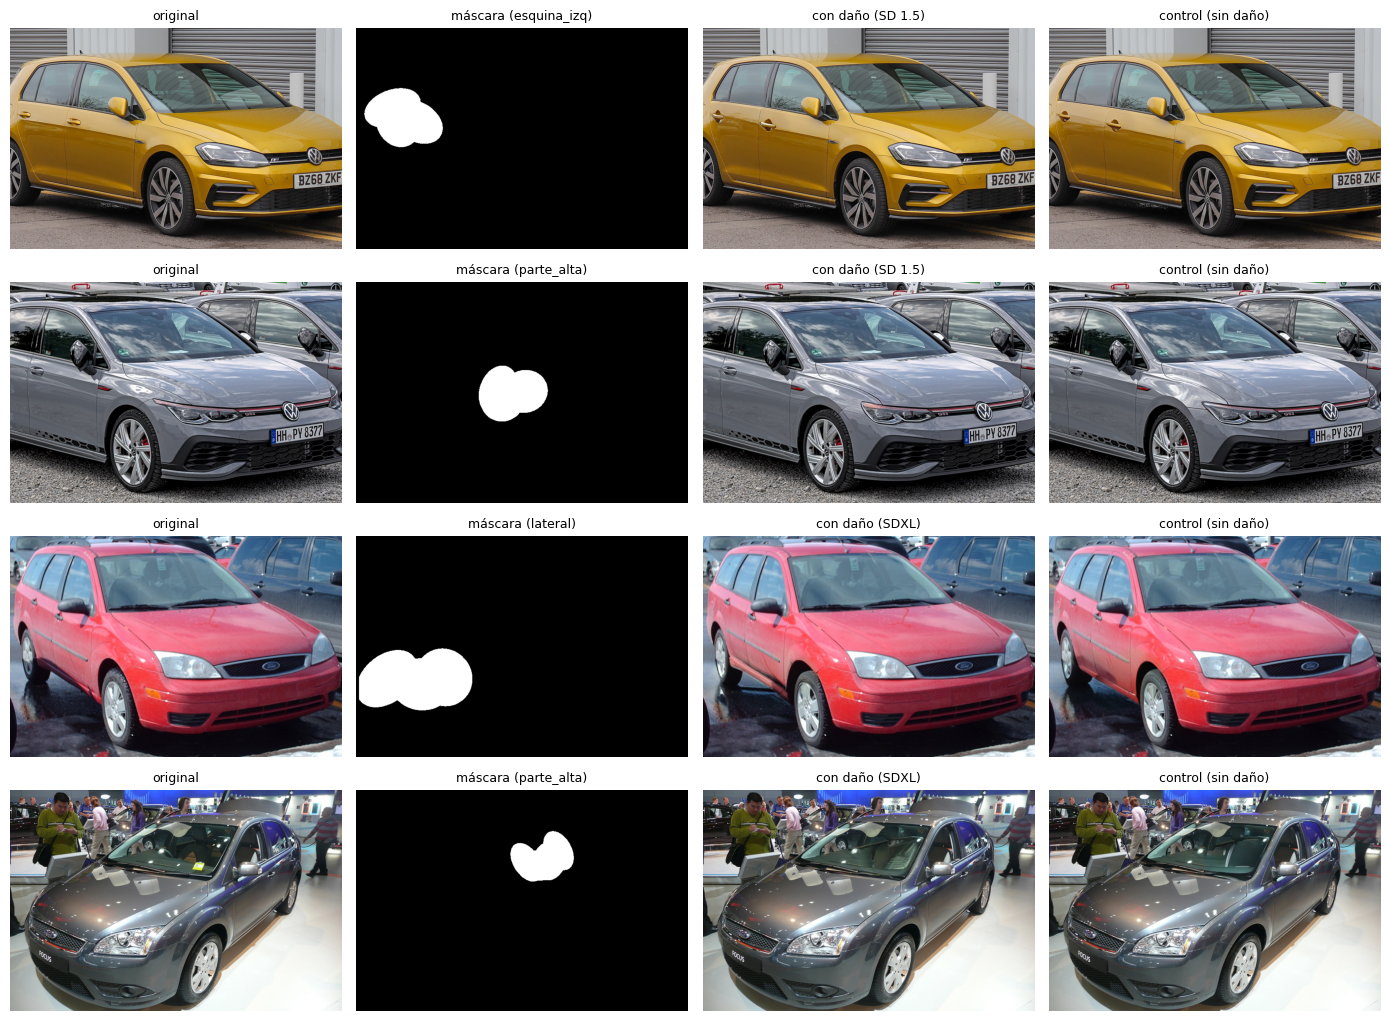

In [17]:
ejemplos = df_falsas[df_falsas["tipo"] == "inpaint_danio"].groupby("modelo").head(2)   # 2 de cada modelo
fig, ax = plt.subplots(len(ejemplos), 4, figsize=(14, 2.6 * max(len(ejemplos), 1)))
ax = np.atleast_2d(ax)
for fila, (_, f) in zip(ax, ejemplos.iterrows()):
    id_ = f["base_id"]
    orig = Image.open(bases.loc[bases["id"] == id_, "ruta_base"].iloc[0])
    m = Image.open(DIR_MASCARAS / f"{id_}_mask.png")
    for a, im, t in zip(fila, [orig, m, Image.open(RAIZ / f["archivo"]), Image.open(DIR_CONTROL / f"{id_}_control.png")],
                        ["original", f"máscara ({f['zona']})", f"con daño ({'SDXL' if 'xl' in f['modelo'] else 'SD 1.5'})", "control (sin daño)"]):
        a.imshow(im, cmap="gray" if im.mode == "L" else None); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Autos 100 % generados por IA

Con **SDXL-turbo** (texto a imagen en 4 pasos) se generan autos completos con el mismo tamaño de 768×512, la mitad con daño y la mitad sin daño. Los prompts imitan el estilo de las fotos reales (autos estacionados, luz natural, foto de celular) para que el contenido no delate la clase.

Se guardan como `ia0001.png`, cada una con su propio grupo, ya que no tienen una foto original asociada.

In [18]:
# [CARGA_MODELO] Texto a imagen
from diffusers import AutoPipelineForText2Image

pipe_t2i = AutoPipelineForText2Image.from_pretrained(
    MODELO_T2I, torch_dtype=torch.float16, variant="fp16").to("cuda")
pipe_t2i.set_progress_bar_config(disable=True)
print("Modelo texto->imagen cargado:", MODELO_T2I)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Modelo texto->imagen cargado: stabilityai/sdxl-turbo


In [19]:
MARCAS_EN = ["Toyota Corolla", "Volkswagen Golf", "Chevrolet Onix", "Ford Focus", "Peugeot 208",
             "Renault Sandero", "Fiat Cronos", "Honda Civic", "Nissan Versa", "Hyundai i10"]
COLORES_EN = ["white", "silver", "black", "red", "dark blue", "gray", "beige"]
ANGULOS_EN = ["front three-quarter view", "side view", "rear three-quarter view", "front view"]
FONDOS_EN = ["parked on a residential street", "in a parking lot", "in a driveway", "parked on a city street"]
DANOS_IA_EN = ["with a dented bumper", "with deep scratches on the door", "with a crumpled fender",
               "with a broken headlight", "with a cracked bumper and scuffed paint"]

def prompt_ia(con_danio, rng):
    p = (f"photo of a {rng.choice(COLORES_EN)} {rng.choice(MARCAS_EN)} car, {rng.choice(ANGULOS_EN)}, "
         f"{rng.choice(FONDOS_EN)}")
    if con_danio:
        p += ", " + str(rng.choice(DANOS_IA_EN))
    return p + ", taken with a smartphone, natural daylight, realistic"

t0 = time.time()
for i in range(1, N_IA + 1):
    ruta = DIR_IA / f"ia{i:04d}.png"
    if ruta.exists():
        continue
    rng = np.random.default_rng(SEMILLA * 1000 + i)
    con_danio = i % 2 == 0
    prompt = prompt_ia(con_danio, rng)
    semilla = int(rng.integers(0, 2**31 - 1))
    gen = torch.Generator(device=GEN_DEVICE).manual_seed(semilla)
    img = pipe_t2i(prompt=prompt, height=CANVAS_H, width=CANVAS_W, num_inference_steps=4,
                   guidance_scale=0.0, generator=gen).images[0].convert("RGB")
    if np.asarray(img).mean() < 3:
        continue
    img.save(ruta)
    registrar({"archivo": str(ruta.relative_to(RAIZ)), "tipo": "ia_danio" if con_danio else "ia_sano",
               "base_id": f"ia{i:04d}", "danio": int(con_danio), "zona": "", "mascara_frac": 0.0,
               "prompt": prompt, "seed": semilla, "modelo": MODELO_T2I, "pasos": 4, "guidance": 0.0,
               "timestamp": datetime.utcnow().isoformat()})
    if i % 20 == 0:
        guardar_manifest()
        print(f"{i}/{N_IA} imágenes IA ({time.time() - t0:.0f}s)")
guardar_manifest()

del pipe_t2i
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Listo.")

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
/tmp/ipykernel_3073/2143348891.py:34: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to repres

Listo.


## 6. Resumen y chequeo visual

Imágenes falsas generadas:
tipo
ia_danio           2
ia_sano            2
inpaint_control    4
inpaint_danio      4


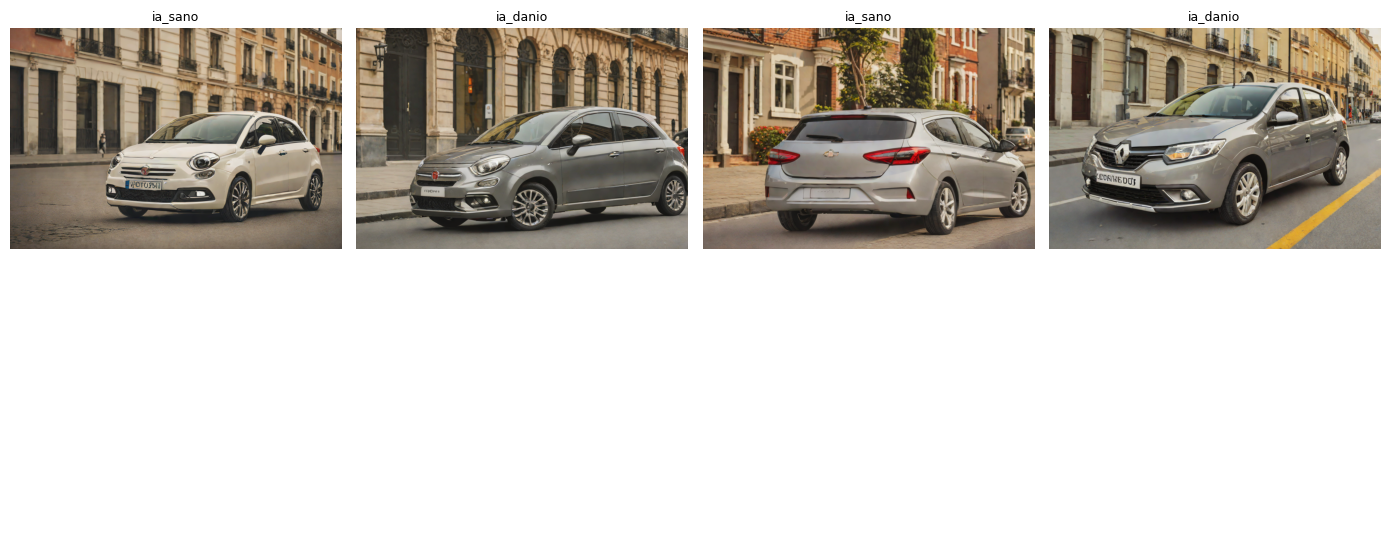

Guardado en: /content/drive/MyDrive/deteccion-fraude-v2/02_falsas/manifest_falsas.csv


In [20]:
df_falsas = pd.read_csv(MANIFEST_FALSAS)
print("Imágenes falsas generadas:")
print(df_falsas.groupby(["tipo"]).size().to_string())

ia = df_falsas[df_falsas["tipo"].isin(["ia_danio", "ia_sano"])].head(8)
if len(ia):
    fig, ax = plt.subplots(2, 4, figsize=(14, 5.5))
    for a, (_, f) in zip(ax.flatten(), ia.iterrows()):
        a.imshow(Image.open(RAIZ / f["archivo"])); a.set_title(f["tipo"], fontsize=9); a.axis("off")
    for a in ax.flatten()[len(ia):]:
        a.axis("off")
    plt.tight_layout(); plt.show()
print("Guardado en:", MANIFEST_FALSAS)

## 7. Próximos pasos

- Los parámetros de generación (`MODELOS_INPAINT`, `PROMPTS_DANIO` y el tamaño de máscara `MIN_FRAC_MASCARA`/`MAX_FRAC_MASCARA`) se ajustan según los chequeos visuales: ediciones demasiado evidentes o sin daño visible indican que hay que modificarlos.
- Con `PRUEBA_RAPIDA = False` se genera el conjunto completo.
- El **notebook 3** une las imágenes reales y las manipuladas, aplica la misma compresión a todas y arma el dataset final.